# EDA — World Happiness Report 2015–2019 (Part A, Step 1)

**Objective:** analyze the quality of the 5 raw files (`data/raw/2015.csv` … `2019.csv`) before cleaning:
schema and column order per year, data types, missing values, duplicates, impossible/suspicious values,
outliers, distributions by year and hygiene of country names.

**Scope of this notebook:** analysis only. It **does not write** any processed file; cleaning and the
unified dataset are part of the next step. Raw data is read-only.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Root of the project (notebook lives in notebooks/ under the repo root)
ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent

RAW = ROOT / "data" / "raw"
YEARS = [2015, 2016, 2017, 2018, 2019]
EXPECTED_ROWS = {2015: 158, 2016: 157, 2017: 155, 2018: 156, 2019: 156}
FEATURES = ["gdp", "family", "health", "freedom", "generosity", "corruption", "happiness_score"]

pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 50)
sns.set_theme(style="white", rc={
    "axes.grid": True, "grid.color": "#EAEAEA", "grid.linewidth": 0.8,
    "axes.edgecolor": "#CCCCCC",
    "text.color": "#333333", "axes.labelcolor": "#333333",
    "xtick.color": "#555555", "ytick.color": "#555555",
    "axes.titlesize": 11.5, "axes.titlecolor": "#2B2B2B",
})
# Fixed, harmonious palette per report year and clean panel titles
YEAR_PALETTE = {2015: "#B8653B", 2016: "#3E78B2", 2017: "#767E8A",
                2018: "#468966", 2019: "#B8863B"}
FEATURE_LABELS = {
    "gdp": "GDP per Capita", "family": "Social Support (Family)",
    "health": "Healthy Life Expectancy", "freedom": "Freedom",
    "generosity": "Generosity", "corruption": "Perceptions of Corruption",
    "happiness_score": "Happiness Score (Target)",
}
print("ROOT =", ROOT)

ROOT = C:\Users\juans\Downloads\ETL - Trabajos\Corte3\Workshop-3


## 1. Files, row counts and absence of `year`

The source files **do not have** any year column: the year must be added later from the
file name. Row counts were reported by the team as 158 / 157 / 155 / 156 / 156 (782 in total,
data rows, header excluded).

In [2]:
frames = {}   # year -> raw dataframe (kept exactly as read)
INV_COL = {}  # year -> name of the raw country column

for y in YEARS:
    df = pd.read_csv(RAW / f"{y}.csv")          # extraction later will select BY NAME
    frames[y] = df
    INV_COL[y] = "Country or region" if "Country or region" in df.columns else "Country"

summary = pd.DataFrame({
    "file": [f"{y}.csv" for y in YEARS],
    "n_rows": [len(frames[y]) for y in YEARS],
    "n_cols": [frames[y].shape[1] for y in YEARS],
    "has_year_column": [any(c.lower() == "year" for c in frames[y].columns) for y in YEARS],
    "country_column": [INV_COL[y] for y in YEARS],
}, index=YEARS)
summary.index.name = "year"
summary

,file,n_rows,n_cols,has_year_column,country_column
year,,,,,
2015,2015.csv,158,12,False,Country
2016,2016.csv,157,13,False,Country
2017,2017.csv,155,12,False,Country
2018,2018.csv,156,9,False,Country or region
2019,2019.csv,156,9,False,Country or region


In [3]:
for y in YEARS:
    ok = len(frames[y]) == EXPECTED_ROWS[y]
    print(f"{y}: {len(frames[y]):3d} rows (expected {EXPECTED_ROWS[y]:3d}) -> {'PASS' if ok else 'FAIL'}")
print("TOTAL:", sum(len(frames[y]) for y in YEARS), "(expected 782)")

no_year = all(not summary.loc[y, "has_year_column"] for y in YEARS)
print("No file carries a 'year' column ->", "PASS" if no_year else "FAIL")

2015: 158 rows (expected 158) -> PASS
2016: 157 rows (expected 157) -> PASS
2017: 155 rows (expected 155) -> PASS
2018: 156 rows (expected 156) -> PASS
2019: 156 rows (expected 156) -> PASS
TOTAL: 782 (expected 782)
No file carries a 'year' column -> PASS


## 2. Schema per year: exact names and column ORDER

Column **order** differs between years (e.g. the corruption/Trust column comes *before*
`Generosity` in 2015–2016 and *after* it in 2017–2019; 2018–2019 put the rank column first).
Selection in this project always reads columns **by name**, never by position.

In [4]:
COLS = {y: list(frames[y].columns) for y in YEARS}
for y in YEARS:
    print(f"{y}: {COLS[y]}")

2015: ['Country', 'Region', 'Happiness Rank', 'Happiness Score', 'Standard Error', 'Economy (GDP per Capita)', 'Family', 'Health (Life Expectancy)', 'Freedom', 'Trust (Government Corruption)', 'Generosity', 'Dystopia Residual']
2016: ['Country', 'Region', 'Happiness Rank', 'Happiness Score', 'Lower Confidence Interval', 'Upper Confidence Interval', 'Economy (GDP per Capita)', 'Family', 'Health (Life Expectancy)', 'Freedom', 'Trust (Government Corruption)', 'Generosity', 'Dystopia Residual']
2017: ['Country', 'Happiness.Rank', 'Happiness.Score', 'Whisker.high', 'Whisker.low', 'Economy..GDP.per.Capita.', 'Family', 'Health..Life.Expectancy.', 'Freedom', 'Generosity', 'Trust..Government.Corruption.', 'Dystopia.Residual']
2018: ['Overall rank', 'Country or region', 'Score', 'GDP per capita', 'Social support', 'Healthy life expectancy', 'Freedom to make life choices', 'Generosity', 'Perceptions of corruption']
2019: ['Overall rank', 'Country or region', 'Score', 'GDP per capita', 'Social sup

In [5]:
# Column-set differences between consecutive years
for a, b in zip(YEARS[:-1], YEARS[1:]):
    sa, sb = set(COLS[a]), set(COLS[b])
    print(f"{a} vs {b}: only in {a}: {sorted(sa - sb)} | only in {b}: {sorted(sb - sa)}")

2015 vs 2016: only in 2015: ['Standard Error'] | only in 2016: ['Lower Confidence Interval', 'Upper Confidence Interval']
2016 vs 2017: only in 2016: ['Dystopia Residual', 'Economy (GDP per Capita)', 'Happiness Rank', 'Happiness Score', 'Health (Life Expectancy)', 'Lower Confidence Interval', 'Region', 'Trust (Government Corruption)', 'Upper Confidence Interval'] | only in 2017: ['Dystopia.Residual', 'Economy..GDP.per.Capita.', 'Happiness.Rank', 'Happiness.Score', 'Health..Life.Expectancy.', 'Trust..Government.Corruption.', 'Whisker.high', 'Whisker.low']
2017 vs 2018: only in 2017: ['Country', 'Dystopia.Residual', 'Economy..GDP.per.Capita.', 'Family', 'Freedom', 'Happiness.Rank', 'Happiness.Score', 'Health..Life.Expectancy.', 'Trust..Government.Corruption.', 'Whisker.high', 'Whisker.low'] | only in 2018: ['Country or region', 'Freedom to make life choices', 'GDP per capita', 'Healthy life expectancy', 'Overall rank', 'Perceptions of corruption', 'Score', 'Social support']
2018 vs 2019:

### 2.1 Data types really parsed

Every file must yield: the rank column as integer, the country (and `Region` in 2015–2016 only)
as text, and ALL remaining columns parsed as **float64**. A single stray string would turn a
whole numeric column into `object` (e.g. through a comma decimal), so this check also rules
out that failure mode. 2017 uses R-style quoted headers (`Economy..GDP.per.Capita.`) and
15-decimal floats; the second block below confirms they still parse as floats.

In [6]:
dtype_table = pd.DataFrame({y: pd.Series(frames[y].dtypes.astype(str)) for y in YEARS}).fillna("-")
dtype_table.index.name = "column"
dtype_table

,2015,2016,2017,2018,2019
column,,,,,
Country,object,object,object,-,-
Country or region,-,-,-,object,object
Dystopia Residual,float64,float64,-,-,-
Dystopia.Residual,-,-,float64,-,-
Economy (GDP per Capita),float64,float64,-,-,-
Economy..GDP.per.Capita.,-,-,float64,-,-
Family,float64,float64,float64,-,-
Freedom,float64,float64,float64,-,-
Freedom to make life choices,-,-,-,float64,float64


In [7]:
type_ops_ok = True
for y in YEARS:
    df = frames[y]
    dtypes = df.dtypes.astype(str)
    obj_cols = sorted(dtypes[dtypes == "object"].index)
    int_cols = sorted(dtypes[dtypes == "int64"].index)
    float_cols = sorted(dtypes[dtypes == "float64"].index)
    text_cols = {INV_COL[y]} | ({"Region"} if "Region" in df.columns else set())
    numeric_ok = all(d in ("int64", "float64") for c, d in dtypes.items() if c not in text_cols)
    keys_ok = len(int_cols) == 1 and set(obj_cols) == text_cols and len(float_cols) > 0
    type_ops_ok = type_ops_ok and numeric_ok and keys_ok
    print(f"{y}: object={obj_cols} | int={int_cols} | n_float_cols={len(float_cols)} "
          f"-> numeric-all-numeric-dtype: {'PASS' if numeric_ok else 'FAIL'} "
          f"(single int key + pure text columns): {'PASS' if keys_ok else 'FAIL'}")
print("=> every numeric column parsed as numeric in every file ->",
      "PASS" if type_ops_ok else "FAIL")

2015: object=['Country', 'Region'] | int=['Happiness Rank'] | n_float_cols=9 -> numeric-all-numeric-dtype: PASS (single int key + pure text columns): PASS
2016: object=['Country', 'Region'] | int=['Happiness Rank'] | n_float_cols=10 -> numeric-all-numeric-dtype: PASS (single int key + pure text columns): PASS
2017: object=['Country'] | int=['Happiness.Rank'] | n_float_cols=10 -> numeric-all-numeric-dtype: PASS (single int key + pure text columns): PASS
2018: object=['Country or region'] | int=['Overall rank'] | n_float_cols=7 -> numeric-all-numeric-dtype: PASS (single int key + pure text columns): PASS
2019: object=['Country or region'] | int=['Overall rank'] | n_float_cols=7 -> numeric-all-numeric-dtype: PASS (single int key + pure text columns): PASS
=> every numeric column parsed as numeric in every file -> PASS


In [8]:
# decimal separator check: re-read all cells as raw strings and look for comma decimals
leftover = []
for y in YEARS:
    df_s = pd.read_csv(RAW / f"{y}.csv", dtype=str, keep_default_na=False)
    text_cols = {INV_COL[y]} | ({"Region"} if "Region" in df_s.columns else set())
    for c in df_s.columns:
        if c in text_cols:
            continue
        hits = df_s[c].str.contains(",")
        if hits.any():
            leftover.append((y, c, int(hits.sum())))
print("comma decimals inside numeric cells:",
      leftover if leftover else "none found (decimal separator is '.')")

print()
print("2017 quoted R-style header (first raw line):")
print((RAW / "2017.csv").read_text(encoding="utf-8-sig").splitlines()[0])
print()
print("2017 first data row parsed, high-precision values preserved as float64:")
first_data_2017 = pd.read_csv(RAW / "2017.csv").iloc[0]
for k, v in first_data_2017.items():
    print(f"  {k:<35} {v!r}")

comma decimals inside numeric cells:

 none found (decimal separator is '.')

2017 quoted R-style header (first raw line):
"Country","Happiness.Rank","Happiness.Score","Whisker.high","Whisker.low","Economy..GDP.per.Capita.","Family","Health..Life.Expectancy.","Freedom","Generosity","Trust..Government.Corruption.","Dystopia.Residual"

2017 first data row parsed, high-precision values preserved as float64:
  Country                             'Norway'
  Happiness.Rank                      np.int64(1)
  Happiness.Score                     np.float64(7.53700017929077)
  Whisker.high                        np.float64(7.59444482058287)
  Whisker.low                         np.float64(7.47955553799868)
  Economy..GDP.per.Capita.            np.float64(1.61646318435669)
  Family                              np.float64(1.53352355957031)
  Health..Life.Expectancy.            np.float64(0.796666502952576)
  Freedom                             np.float64(0.635422587394714)
  Generosity                          np.float64(0.36201223731

## 3. Unified-schema proposal: name mapping per year and columns to drop

Target unified columns (exact contract order):
`country` (str), `year` (int), `gdp`, `family`, `health`, `freedom`, `generosity`, `corruption` (float64), `happiness_score` (float64).

### 3.1 Column mapping table (selected BY NAME)

| Unified | 2015 / 2016 | 2017 | 2018 / 2019 |
|---|---|---|---|
| `country` | `Country` | `Country` | `Country or region` |
| `happiness_score` | `Happiness Score` | `Happiness.Score` | `Score` |
| `gdp` | `Economy (GDP per Capita)` | `Economy..GDP.per.Capita.` | `GDP per capita` |
| `family` | `Family` | `Family` | `Social support` |
| `health` | `Health (Life Expectancy)` | `Health..Life.Expectancy.` | `Healthy life expectancy` |
| `freedom` | `Freedom` | `Freedom` | `Freedom to make life choices` |
| `generosity` | `Generosity` | `Generosity` | `Generosity` |
| `corruption` | `Trust (Government Corruption)` | `Trust..Government.Corruption.` | `Perceptions of corruption` |
| `year` | *(added from the file name)* | *(added)* | *(added)* |

### 3.2 Columns dropped and why (target leakage)

| Dropped column (years) | Reason |
|---|---|
| `Happiness Rank` (2015–16), `Happiness.Rank` (2017), `Overall rank` (2018–19) | **Target leakage**: the rank is a deterministic function of the score, so the model could "read" the answer through it. Not in the event contract either. |
| `Standard Error` (2015) | **Target leakage**: it is derived from the score distribution (the target's own uncertainty). Single-year column. |
| `Lower Confidence Interval` / `Upper Confidence Interval` (2016) | **Target leakage**: score-derived bounds; they move with the target almost 1-to-1. |
| `Whisker.high` / `Whisker.low` (2017) | **Target leakage**: the same score-derived intervals under a different name. |
| `Dystopia Residual` / `Dystopia.Residual` (2015–17) | **Direct target leakage**: it is literally `score − (sum of the six factors)`; keeping it would constrain the model to reproduce the score by construction. |
| `Region` (2015–16) | Absent in 2017–2019 (can't be a shared feature) and not part of the event contract. Kept only as a future optional attribute of `dim_country` (database layer), never as a model feature. |

In [9]:
MAP = {
    2015: {"Country": "country", "Happiness Score": "happiness_score",
           "Economy (GDP per Capita)": "gdp", "Family": "family",
           "Health (Life Expectancy)": "health", "Freedom": "freedom",
           "Trust (Government Corruption)": "corruption", "Generosity": "generosity"},
    2016: {"Country": "country", "Happiness Score": "happiness_score",
           "Economy (GDP per Capita)": "gdp", "Family": "family",
           "Health (Life Expectancy)": "health", "Freedom": "freedom",
           "Trust (Government Corruption)": "corruption", "Generosity": "generosity"},
    2017: {"Country": "country", "Happiness.Score": "happiness_score",
           "Economy..GDP.per.Capita.": "gdp", "Family": "family",
           "Health..Life.Expectancy.": "health", "Freedom": "freedom",
           "Trust..Government.Corruption.": "corruption", "Generosity": "generosity"},
    2018: {"Country or region": "country", "Score": "happiness_score",
           "GDP per capita": "gdp", "Social support": "family",
           "Healthy life expectancy": "health", "Freedom to make life choices": "freedom",
           "Perceptions of corruption": "corruption", "Generosity": "generosity"},
    2019: {"Country or region": "country", "Score": "happiness_score",
           "GDP per capita": "gdp", "Social support": "family",
           "Healthy life expectancy": "health", "Freedom to make life choices": "freedom",
           "Perceptions of corruption": "corruption", "Generosity": "generosity"},
}
UNIFIED = ["country", "year", "gdp", "family", "health",
           "freedom", "generosity", "corruption", "happiness_score"]

# every mapping key must exist BY NAME in its file, and the mapped set must be exactly
# the unified schema + 'year'
for y in YEARS:
    missing_keys = set(MAP[y]) - set(frames[y].columns)
    produced = set(MAP[y].values()) | {"year"}
    print(f"{y}: all mapping keys present -> {'PASS' if not missing_keys else 'FAIL ' + str(sorted(missing_keys))}; "
          f"produces exactly the unified schema -> {'PASS' if produced == set(UNIFIED) else 'FAIL'}")

INV_MAP = {y: {uni: orig for orig, uni in MAP[y].items()} for y in YEARS}

2015: all mapping keys present -> PASS; produces exactly the unified schema -> PASS
2016: all mapping keys present -> PASS; produces exactly the unified schema -> PASS
2017: all mapping keys present -> PASS; produces exactly the unified schema -> PASS
2018: all mapping keys present -> PASS; produces exactly the unified schema -> PASS
2019: all mapping keys present -> PASS; produces exactly the unified schema -> PASS


## 4. Missing values in EVERY column of EVERY file

A gap counts as missing if it is a parsed `NaN`, an empty string, a whitespace-only string or
one of the sentinels `N/A`, `NA`, `-`, `null`. Published zeros are NOT counted as missing
here; they are audited separately in subsection 4.2 below.

In [10]:
SENTINELS = {"", "n/a", "na", "-", "null", "nan"}   # compared lower-cased on stripped strings

scanned = []
for y in YEARS:
    df = frames[y]
    # parsed NaN counts straight from the numeric layer
    for c, cnt in df.isna().sum().items():
        if cnt:
            scanned.append({"year": y, "column": c, "kind": "NaN/nul", "count": int(cnt)})
    # string sentinels in the object layer (write cells as RAW text to not miss anything)
    df_raw = pd.read_csv(RAW / f"{y}.csv", dtype=str, keep_default_na=False)
    for c in df_raw.columns:
        s = df_raw[c].str.strip().str.lower()
        for value in SENTINELS:
            hits = s[s == value]
            if len(hits):
                scanned.append({"year": y, "column": c, "kind": f"sentinel {value!r}", "count": len(hits)})

if scanned:
    left_detail = pd.DataFrame(scanned).sort_values(["year", "kind"]).reset_index(drop=True)
    display(left_detail)
else:
    print("No missing values found in any file.")

,year,column,kind,count
0,2018,Perceptions of corruption,NaN/nul,1
1,2018,Perceptions of corruption,sentinel 'n/a',1


In [11]:
# Exact detail of every truly missing cell: file row position, country and its rank
missing_detail = []
for y in YEARS:
    df = frames[y]
    for c in df.columns:
        mask = df[c].isna()
        for idx in df.index[mask]:
            row = df.loc[idx]
            rank_col = next((x for x in df.columns if "ank" in x), None)
            missing_detail.append({
                "year": y,
                "data_row_0based": int(idx),
                "country": row[INV_COL[y]],
                "missing_column": c,
                "rank_same_row": (int(row[rank_col]) if rank_col is not None else None),
            })
missing_detail = pd.DataFrame(missing_detail)
missing_detail

,year,data_row_0based,country,missing_column,rank_same_row
0,2018,19,United Arab Emirates,Perceptions of corruption,20


In [12]:
# Full-column view: NaN counts per column and year (zeros everywhere except that one cell)
nan_matrix = pd.DataFrame({y: frames[y].isna().sum() for y in YEARS}).fillna(0).astype(int)
nan_matrix.index.name = "column"
nan_matrix[nan_matrix.sum(axis=1) > 0]

,2015,2016,2017,2018,2019
column,,,,,
Perceptions of corruption,0,0,0,1,0


### 4.1 Decision proposal for missing values (Decision D4)

Exactly **one** missing value exists in the whole dataset: `2018`,
`United Arab Emirates`, `Perceptions of corruption` (see the tables above). That single
`NaN` is not a silent empty read: in `2018.csv` the raw text of that cell is the literal
sentinel `'N/A'` (raw-string scan in the first table of this section), and
`pandas.read_csv()` parses it into this one `NaN`. No *other* sentinel (`NA`, `-`, `null`,
empty or whitespace-only) and no other missing cell exists anywhere in the five files.

**Proposed decision for D4 — drop the row, do not impute:**

1. One row out of 782 (0.13 %) is negligible for a 782-row training set;
2. `Perceptions of corruption` is one of the six model features: imputing a subjective index
   (median, regional average, country trend) would fabricate a value the report never
   published, and any imputation built from other features would use information in a way
   the streaming contract cannot reproduce at inference time (the event has a `corruption`
   field that arrives or doesn't — the model must not depend on fill-in strategies);
3. the row remains perfectly usable at the raw layer; only the training set loses it.

Consequence for the cleaning step: 782 → **781 rows**, logging the single dropped row
(country `United Arab Emirates`, year 2018, column `corruption`).

### 4.2 Audit of zeros (can a published zero really mean "missing"?)

The report can publish a genuine `0.00` when a factor hits its floor, so every zero is
checked **per country and per year** before treating it as data loss. A "missing-looking"
zero would appear as an isolated drop in a random cell; a "published" zero tends to be
concentrated in the same low-rank countries and repeated across years.

In [13]:
zero_rows = []
for y in YEARS:
    df = frames[y]
    for uni in FEATURES:
        orig = INV_MAP[y][uni]
        for idx in df.index[df[orig] == 0]:
            zero_rows.append({"year": y, "country": df.loc[idx, INV_COL[y]],
                              "feature": uni, "value": 0.0})
zeros_audit = pd.DataFrame(zero_rows)
print("total zero cells among the 6 features + target:", len(zeros_audit))
counts = zeros_audit.groupby(["feature", "year"]).size().unstack(fill_value=0)
counts.reindex(columns=YEARS).fillna(0).astype(int)

total zero cells among the 6 features + target: 31


year,2015,2016,2017,2018,2019
feature,,,,,
corruption,1,1,1,2,1
family,1,1,1,1,1
freedom,1,1,1,1,1
gdp,1,1,1,1,1
generosity,1,1,1,1,1
health,1,1,1,1,1


In [14]:
# Same countries repeat across years — a signature of published floor values, not data loss
piv = zeros_audit.groupby(["country", "feature"]).size().unstack(fill_value=0)
piv["cells"] = piv.sum(axis=1)
piv.sort_values("cells", ascending=False)

feature,corruption,family,freedom,gdp,generosity,health,cells
country,,,,,,,
Central African Republic,0,4,0,1,0,0,5
Greece,0,0,0,0,5,0,5
Bosnia and Herzegovina,3,0,0,0,0,0,3
Somalia,0,0,0,3,0,0,3
Sierra Leone,0,0,0,0,0,3,3
Angola,0,0,2,0,0,0,2
Moldova,2,0,0,0,0,0,2
Indonesia,1,0,0,0,0,0,1
Congo (Kinshasa),0,0,0,1,0,0,1


In [15]:
# Spot check of the most repeated case: Greece 'generosity' == 0 in EVERY year 2015-2019
for y in YEARS:
    df = frames[y]
    g = df.loc[df[INV_COL[y]] == "Greece", INV_MAP[y]["generosity"]]
    print(y, "Greece", INV_MAP[y]["generosity"], "=", (float(g.iloc[0]) if len(g) else None))

2015 Greece Generosity = 0.0
2016 Greece Generosity = 0.0
2017 Greece Generosity = 0.0
2018 Greece Generosity = 0.0
2019 Greece Generosity = 0.0


**Reading of the zero audit**

* Zeros concentrate in the low-rank tail — per the audit tables above: Somalia, Central
  African Republic, Sierra Leone, Lesotho, Angola, Afghanistan, Moldova, Bosnia and
  Herzegovina, Togo, Sudan, Iraq, Indonesia, Swaziland and Congo (Kinshasa) — and repeat the
  same country across years (Greece `generosity` = 0.0 in *all five* years; Somalia `GDP`
  = 0 in 2016, 2018 and 2019, while 2017 is a nonzero floor value of 0.0226). An accidental
  data loss would prune random cells, not repeat the same country's floor values with the
  rest of its row intact.
* No country holds a full row of zeros in any single year; each row's remaining cells are
  present (the 2018 UAE NaN of §4.1 is the only actual hole).
* **Conclusion / proposal:** keep the zeros as published values — `0` is the legitimate
  minimum of these capped indices, and the event contract validates `>= 0` at inference
  (negative is invalid, zero is not). Only the single NaN of §4.1 is dropped.

## 5. Duplicates

Two levels: exact full-row duplicates, and duplicates on the unified key — inside one file
`year` is constant, so the key is just the country column repeated.

In [16]:
dups = []
for y in YEARS:
    df = frames[y]
    d_full = int(df.duplicated().sum())
    d_key = int(df[INV_COL[y]].duplicated().sum())
    dups.append({"year": y, "full_row_duplicates": d_full, "country_duplicates": d_key,
                 "n_rows": len(df), "n_unique_countries": int(df[INV_COL[y]].nunique())})
pd.DataFrame(dups).set_index("year")

,full_row_duplicates,country_duplicates,n_rows,n_unique_countries
year,,,,
2015,0,0,158,158
2016,0,0,157,157
2017,0,0,155,155
2018,0,0,156,156
2019,0,0,156,156


In [17]:
dup_ok = all(d["full_row_duplicates"] == 0 and d["country_duplicates"] == 0 for d in dups)
print("duplicates inside each single file ->", "NONE (PASS)" if dup_ok else "REVIEW NEEDED")
print("(cross-year (country, year) duplicates cannot occur at the file level: each file")
print(" has a single implicit year and exact country uniqueness, verified above)")

duplicates inside each single file -> NONE (PASS)
(cross-year (country, year) duplicates cannot occur at the file level: each file
 has a single implicit year and exact country uniqueness, verified above)


## 6. Impossible / suspicious values and outliers (IQR)

For every numeric column per year: `min` / `max` (nothing may be negative) and outliers by
the standard rule `value < Q1 − 1.5·IQR` or `value > Q3 + 1.5·IQR`.

In [18]:
stats = {}
for y in YEARS:
    df = frames[y]
    stats[y] = pd.DataFrame({uni: df[INV_MAP[y][uni]] for uni in FEATURES}).agg(["min", "max"]).T
flat = pd.concat({y: stats[y] for y in YEARS})
negatives = flat[flat["min"] < 0]
print("negative values:", "NONE (PASS)" if negatives.empty else negatives)
minmax_pivot = (flat.reset_index()
                  .rename(columns={"level_0": "year", "level_1": "feature"})
                  .pivot(index="feature", columns="year", values=["min", "max"])
                  .round(4))
minmax_pivot

negative values: NONE (PASS)


min                                 max                              
year              2015   2016   2017   2018   2019    2015    2016    2017   2018   2019
feature                                                                                 
corruption       0.000  0.000  0.000  0.000  0.000  0.5519  0.5052  0.4643  0.457  0.453
family           0.000  0.000  0.000  0.000  0.000  1.4022  1.1833  1.6106  1.644  1.624
freedom          0.000  0.000  0.000  0.000  0.000  0.6697  0.6085  0.6582  0.724  0.631
gdp              0.000  0.000  0.000  0.000  0.000  1.6904  1.8243  1.8708  2.096  1.684
generosity       0.000  0.000  0.000  0.000  0.000  0.7959  0.8197  0.8381  0.598  0.566
happiness_score  2.839  2.905  2.693  2.905  2.853  7.5870  7.5260  7.5370  7.632  7.769
health           0.000  0.000  0.000  0.000  0.000  1.0252  0.9528  0.9495  1.030  1.141

In [19]:
iqr_tab = []
for y in YEARS:
    df = frames[y]
    for uni in FEATURES:
        x = df[INV_MAP[y][uni]].dropna()
        q1, q3 = x.quantile([0.25, 0.75])
        iqr = q3 - q1
        low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
        outl = x[(x < low) | (x > high)]
        if len(outl):
            Wei = "; ".join(f"{df.loc[i, INV_COL[y]]}={v:.3f}" for i, v in list(outl.items())[:3])
        else:
            Wei = "-"
        iqr_tab.append({"year": y, "feature": uni, "n_outliers": len(outl),
                        "pct": round(100 * len(outl) / len(x), 1), "examples": Wei})
pd.DataFrame(iqr_tab)

,year,feature,n_outliers,pct,examples
0,2015,gdp,0,0.0,-
1,2015,family,3,1.9,Central African Republic=0.000; Afghanistan=0....
2,2015,health,0,0.0,-
3,2015,freedom,0,0.0,-
4,2015,generosity,2,1.3,Thailand=0.576; Myanmar=0.796
5,2015,corruption,14,8.9,Switzerland=0.420; Denmark=0.484; Norway=0.365
6,2015,happiness_score,0,0.0,-
7,2016,gdp,0,0.0,-
8,2016,family,1,0.6,Togo=0.000
9,2016,health,0,0.0,-


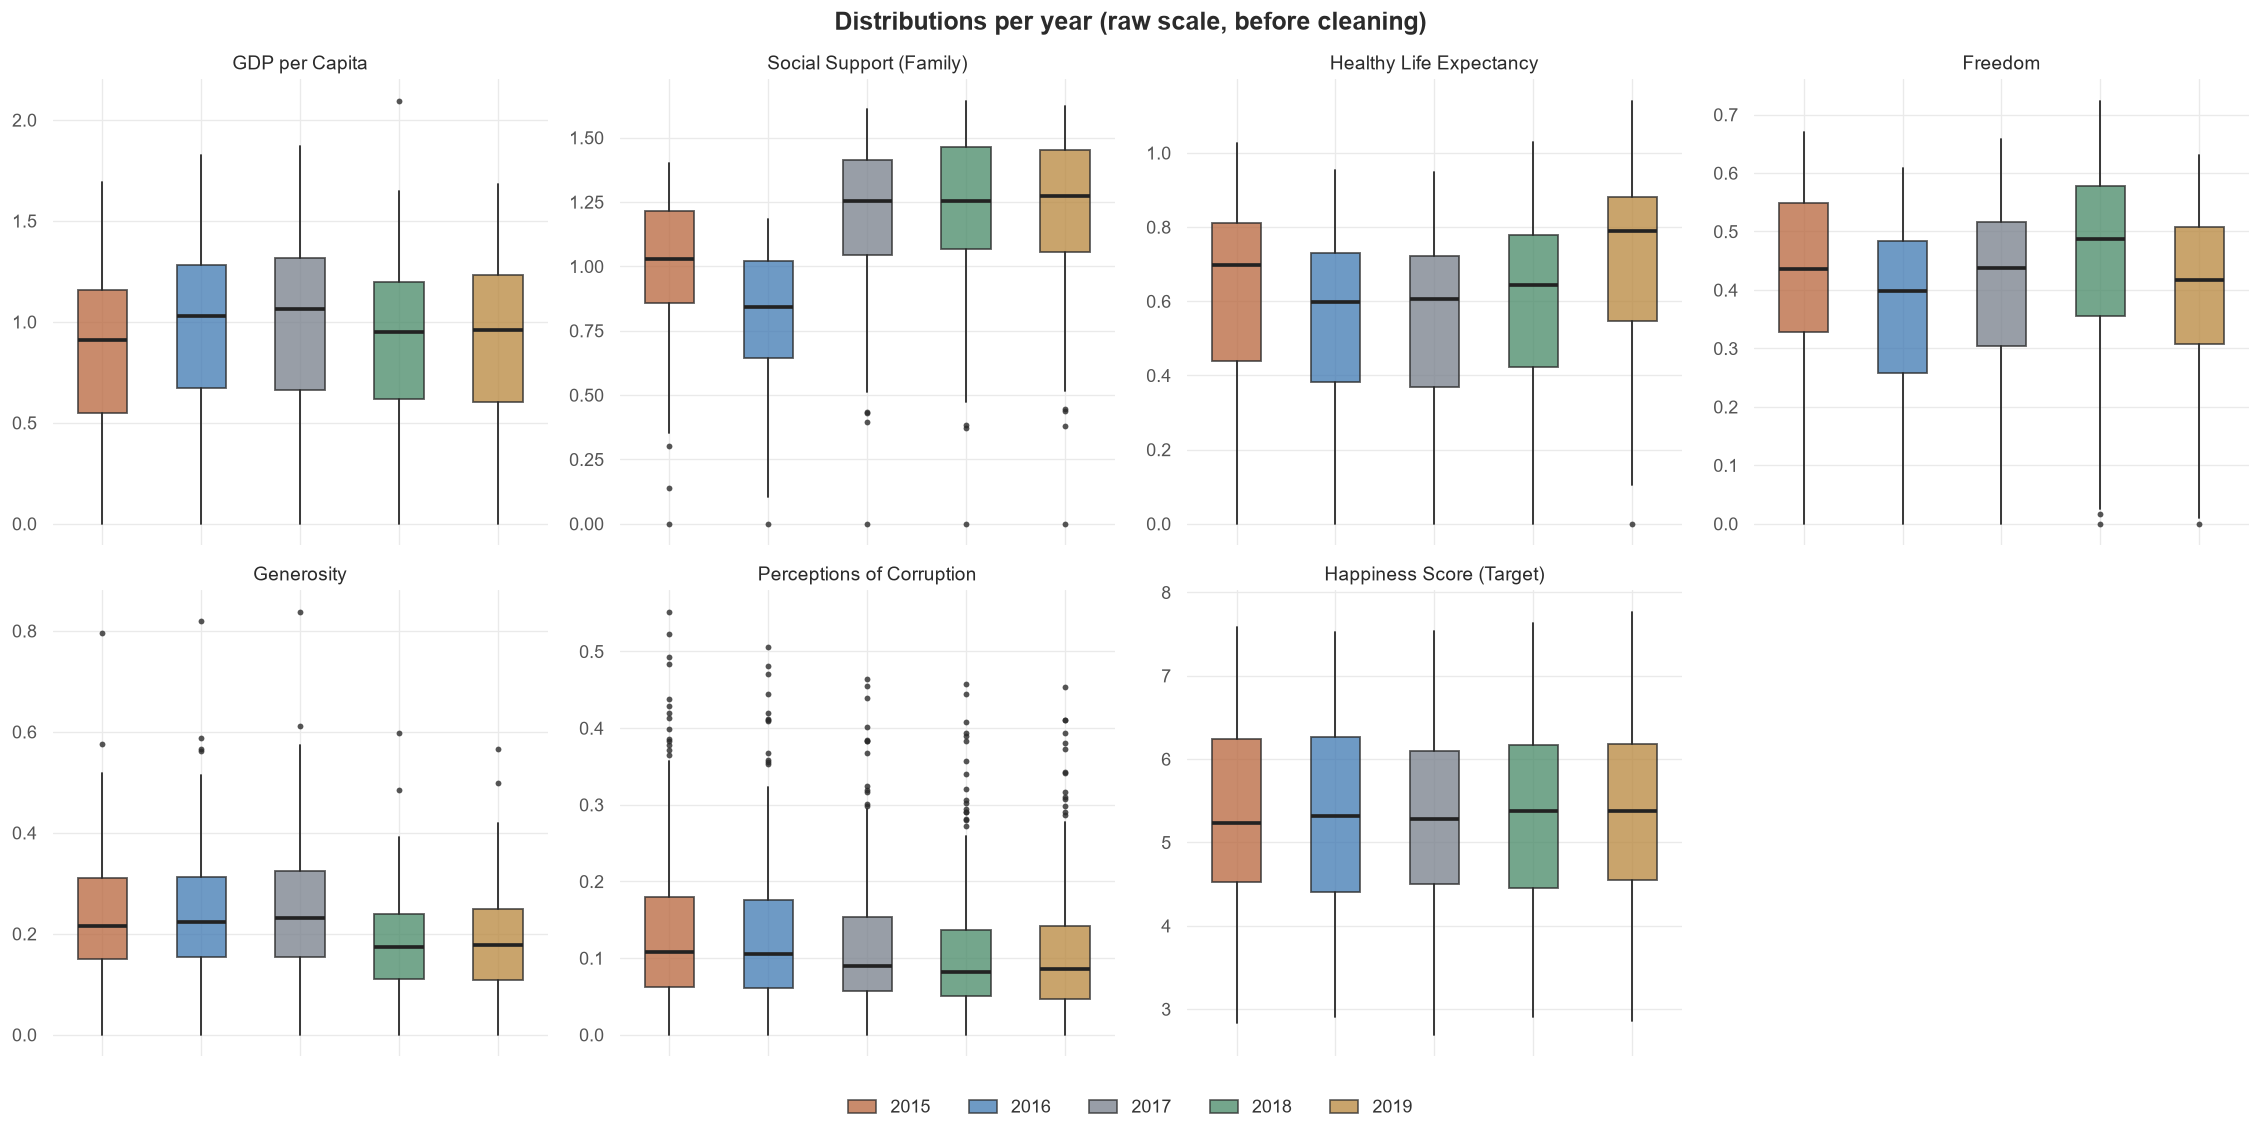

In [20]:
# Boxplots: 6 contract features + target; one panel per feature, boxes side by side per year
from matplotlib.patches import Patch

fig, axes = plt.subplots(2, 4, figsize=(19, 9.5), dpi=120)
fig.suptitle("Distributions per year (raw scale, before cleaning)",
             fontsize=15, fontweight="bold", color="#2B2B2B")
for ax, f in zip(axes.flat, FEATURES):
    data = [frames[y][INV_MAP[y][f]].dropna() for y in YEARS]
    bp = ax.boxplot(
        data, showfliers=True, showcaps=False, patch_artist=True,
        flierprops=dict(marker="o", markersize=3.5, markerfacecolor="#2B2B2B",
                        markeredgecolor="none", alpha=0.8),
        medianprops=dict(color="#222222", linewidth=2.2),
        whiskerprops=dict(color="#2B2B2B", linewidth=1.1),
        boxprops=dict(edgecolor="#2B2B2B", linewidth=1.1),
    )
    for box_patch, y in zip(bp["boxes"], YEARS):
        box_patch.set_facecolor(YEAR_PALETTE[y])
        box_patch.set_alpha(0.75)
    ax.set_title(FEATURE_LABELS[f], fontsize=11.5)
    ax.set_xlabel("")
    ax.set_xticklabels([])               # year labels collapse into the single legend below
sns.despine(left=True, bottom=True)
axes.flat[-1].axis("off")   # empty 8th panel stays blank

handles = [Patch(facecolor=YEAR_PALETTE[y], edgecolor="#2B2B2B", alpha=0.75, label=str(y))
           for y in YEARS]
fig.legend(handles=handles, loc="lower center", ncol=5, frameon=False,
           handlelength=1.6, columnspacing=2.2, fontsize=10.5)
plt.tight_layout(rect=(0, 0.045, 1, 1))
plt.show()

## 7. Distributions per year and scale shifts (`family`, `health`)

The raw samples suggested a scale break: Denmark's `family` jumps 1.16 (2016) → 1.55 (2017)
and its `health` moves 0.79 (2017) → 0.87 (2018) → 1.00 (2019). A same-country split proves
whether the factor-scale itself moved. If whole years shift together, a single global model
on the six raw factors may lose accuracy; the alternative remedies (adding `year` as a
feature, per-year rescaling, or none) are recorded in decision note **D7** for the modelling
phase — this notebook only establishes the evidence.

In [21]:
stable = ["Denmark", "Switzerland", "Norway", "Costa Rica", "Mexico", "Japan"]
rows = []
for y in YEARS:
    df = frames[y]
    for ctry in stable:
        r = df[df[INV_COL[y]] == ctry]
        if not len(r):
            continue
        r = r.iloc[0]
        rows.append({"country": ctry, "year": y,
                     **{f: round(float(r[INV_MAP[y][f]]), 3) for f in FEATURES}})
valley = pd.DataFrame(rows).set_index(["country", "year"])
for f in ("family", "health"):
    print(f"--- {f}: stable countries across years ---")
    print(valley.unstack("year")[f])
    print()

--- family: stable countries across years ---
year          2015   2016   2017   2018   2019
country                                       
Costa Rica   1.238  1.022  1.416  1.459  1.441
Denmark      1.361  1.164  1.551  1.590  1.573
Japan        1.257  1.061  1.436  1.462  1.419
Mexico       0.915  0.715  1.211  1.252  1.323
Norway       1.331  1.127  1.534  1.582  1.582
Switzerland  1.350  1.145  1.517  1.549  1.526

--- health: stable countries across years ---
year          2015   2016   2017   2018   2019
country                                       
Costa Rica   0.860  0.761  0.760  0.817  0.963
Denmark      0.875  0.795  0.793  0.868  0.996
Japan        0.991  0.915  0.913  0.988  1.088
Mexico       0.814  0.711  0.710  0.761  0.861
Norway       0.885  0.796  0.797  0.861  1.028
Switzerland  0.941  0.863  0.858  0.927  1.052



,gdp_mean,gdp_std,family_mean,family_std,health_mean,health_std,freedom_mean,freedom_std,generosity_mean,generosity_std,corruption_mean,corruption_std,happiness_score_mean,happiness_score_std
year,,,,,,,,,,,,,,
2015,0.8461,0.4031,0.9910,0.2724,0.6303,0.2471,0.4286,0.1507,0.2373,0.1267,0.1434,0.1200,5.3757,1.1450
2016,0.9539,0.4126,0.7936,0.2667,0.5576,0.2293,0.3710,0.1455,0.2426,0.1338,0.1376,0.1110,5.3822,1.1417
2017,0.9847,0.4208,1.1889,0.2873,0.5513,0.2371,0.4088,0.1500,0.2469,0.1348,0.1231,0.1017,5.3540,1.1312
2018,0.8914,0.3919,1.2132,0.3024,0.5973,0.2476,0.4545,0.1624,0.1810,0.0985,0.1120,0.0965,5.3759,1.1195
2019,0.9051,0.3984,1.2088,0.2992,0.7252,0.2421,0.3926,0.1433,0.1848,0.0953,0.1106,0.0945,5.4071,1.1131


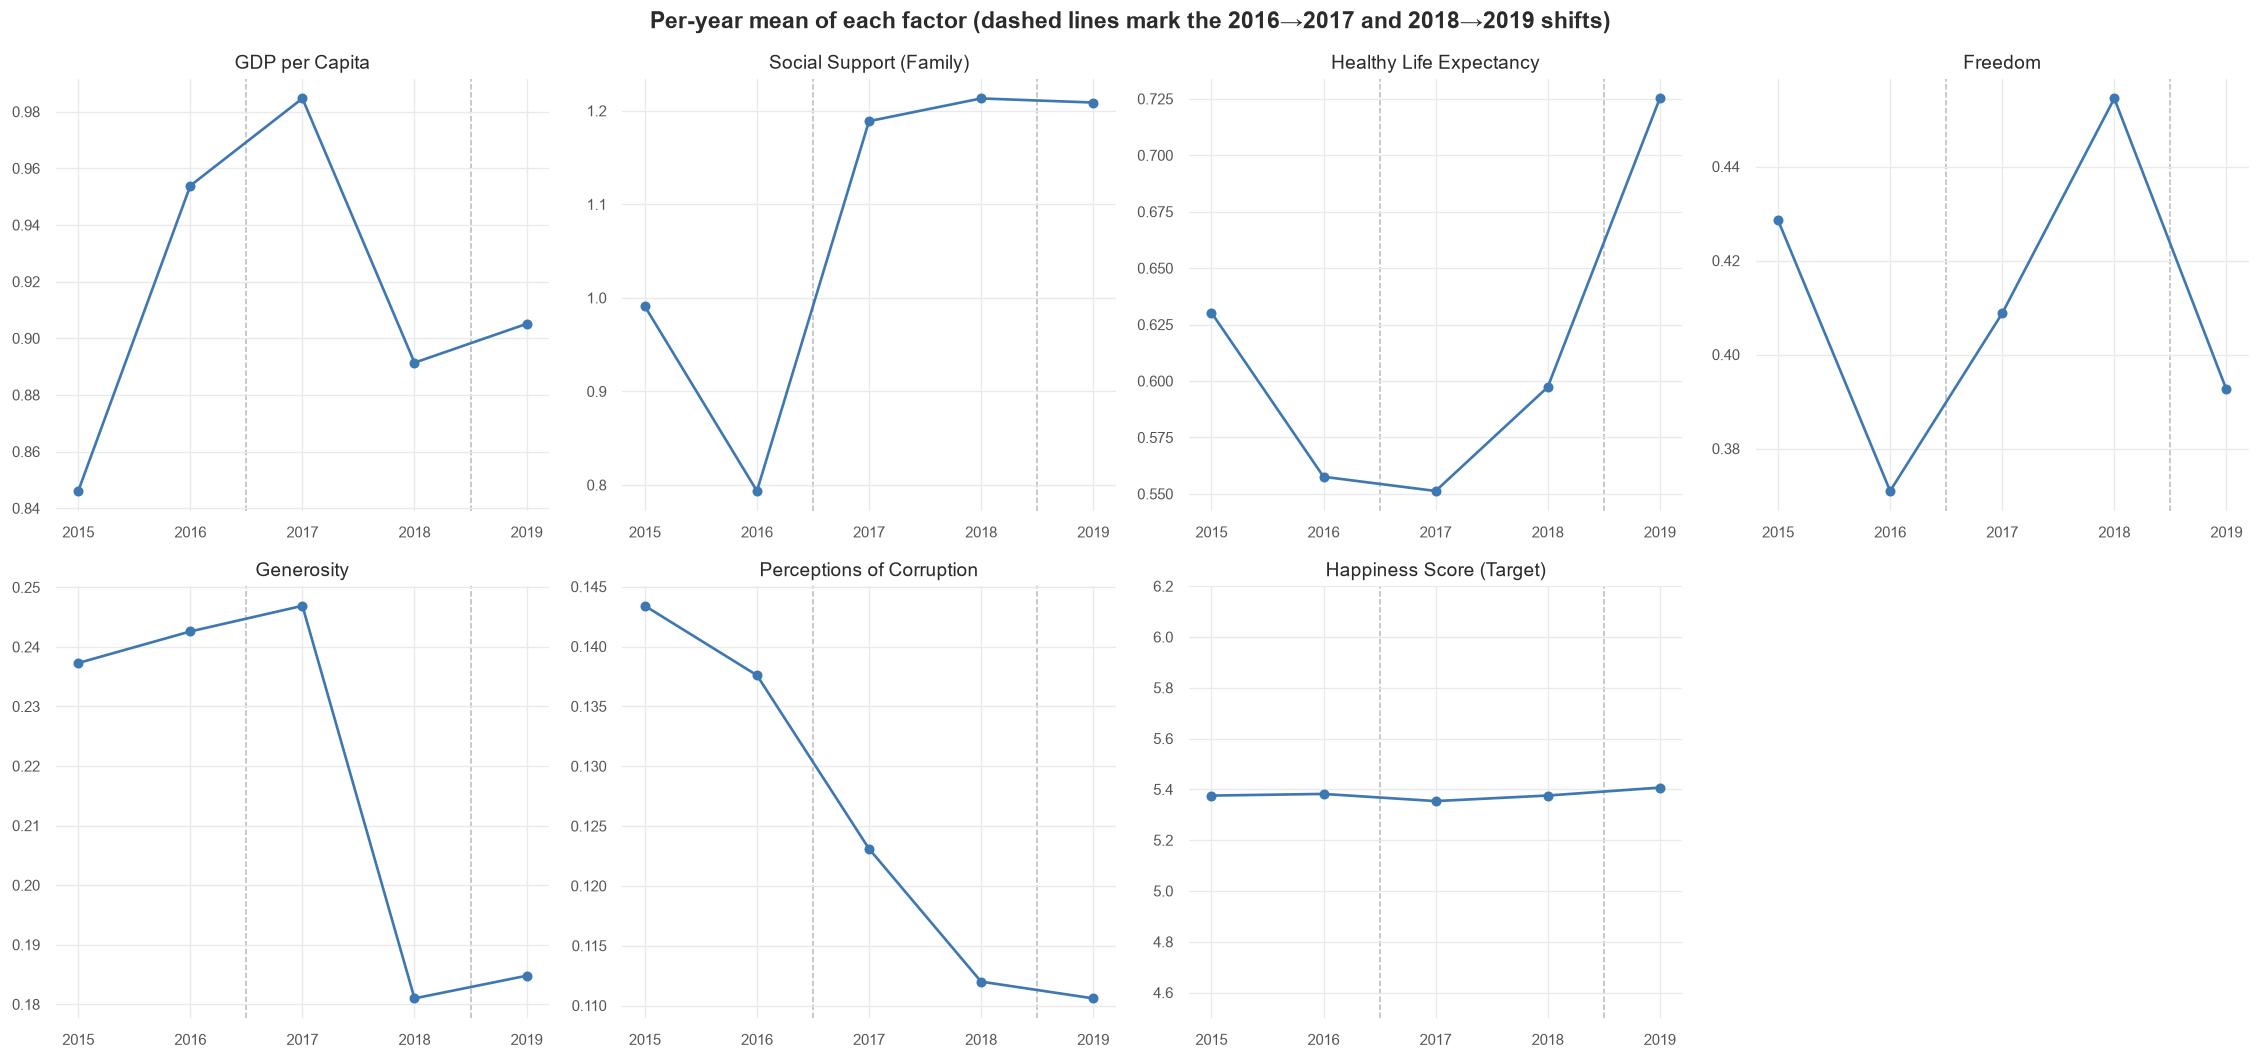

In [22]:
mus = []
for y in YEARS:
    row = {"year": y}
    for f in FEATURES:
        row[f + "_mean"] = round(float(frames[y][INV_MAP[y][f]].mean()), 4)
        row[f + "_std"] = round(float(frames[y][INV_MAP[y][f]].std()), 4)
    mus.append(row)
trend = pd.DataFrame(mus).set_index("year")
display(trend)

fig, axes = plt.subplots(2, 4, figsize=(19, 9), dpi=120)
fig.suptitle("Per-year mean of each factor (dashed lines mark the 2016→2017 and 2018→2019 shifts)",
             fontsize=14, fontweight="bold", color="#2B2B2B")
for ax, f in zip(axes.flat, FEATURES):
    ax.plot(list(trend.index), trend[f + "_mean"].values, marker="o",
            color="#3E78B2", linewidth=1.6, markersize=5)
    ax.set_title(FEATURE_LABELS[f], fontsize=11.5)
    ax.set_xlabel("")
    ax.set_xticks(list(trend.index))
    ax.set_xticklabels([str(y) for y in trend.index], fontsize=9)
    ax.tick_params(axis="y", labelsize=9)
    for v in (2016.5, 2018.5):        # subtle edition-transition markers
        ax.axvline(v, color="#999999", linestyle="--", linewidth=0.9, alpha=0.7, zorder=0)
    if f == "happiness_score":
        ax.set_ylim(4.5, 6.2)         # target panel: honest stability, no extreme auto-zoom
sns.despine(left=True, bottom=True)
axes.flat[-1].axis("off")   # empty 8th panel stays blank
plt.tight_layout()
plt.show()

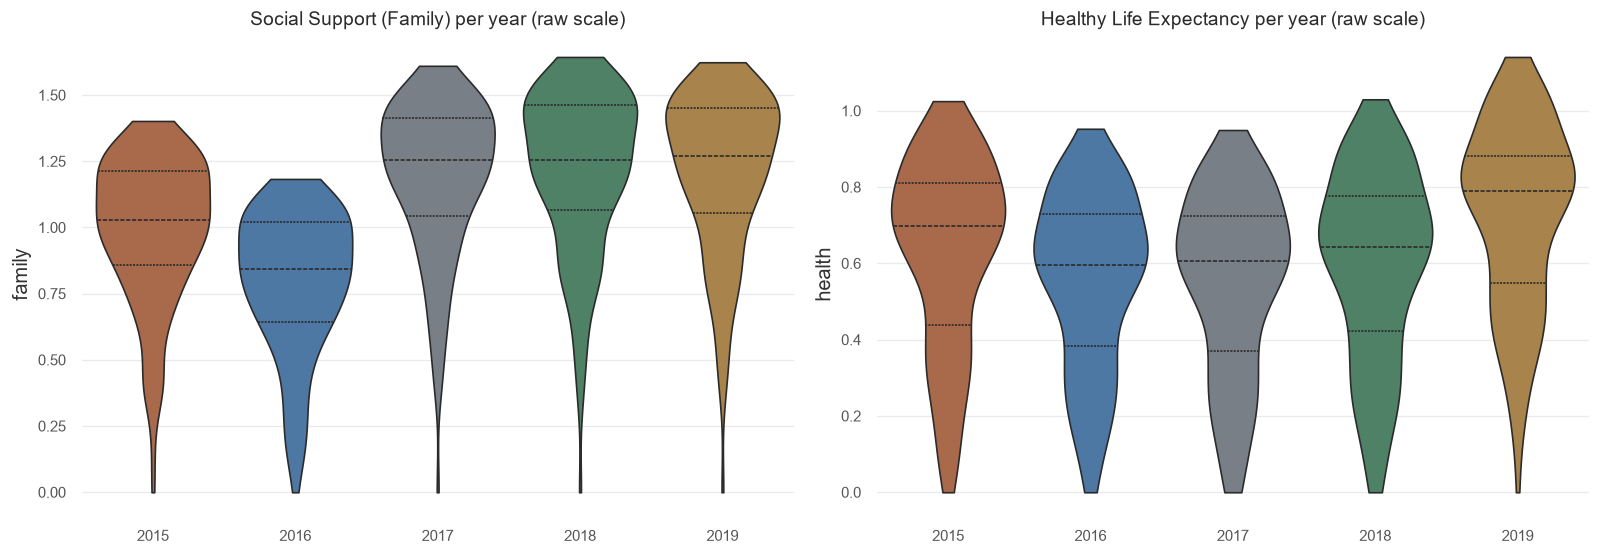

In [23]:
# Same evidence as violins for the two flagged features (clean minimal style, cut=0
# so the density never dips below the real 0.0 floor of the scales)
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.8), dpi=120)
for ax, f in zip(axes, ("family", "health")):
    merged = pd.concat([pd.DataFrame({"year": y, f: frames[y][INV_MAP[y][f]]}) for y in YEARS])
    sns.violinplot(data=merged, x="year", y=f, hue="year", palette=YEAR_PALETTE,
                   legend=False, cut=0, inner="quartile",
                   edgecolor="#2B2B2B", linewidth=1.0, ax=ax)
    ax.set_title(f"{FEATURE_LABELS[f]} per year (raw scale)", fontsize=11.5)
    ax.set_xlabel("")
    ax.tick_params(axis="x", labelsize=9)
    ax.tick_params(axis="y", labelsize=9)
sns.despine(left=True, bottom=True)
plt.tight_layout()
plt.show()

**Reading (evidence gathered for D7)**

* `family`: the per-year mean is *not* stable — 0.991 (2015) → 0.794 (2016) → **1.189 (2017)**
  → 1.213 (2018) → 1.209 (2019). The same pattern shows in every stable country: Denmark
  1.361 → 1.164 → **1.551** → 1.590 → 1.573. A country cannot really lose ~0.2 of "social
  support" in one year and recover ~0.4 the next: the report edition re-cut the factor's
  weighting, most sharply at the 2016→2017 boundary (plus a milder 2015→2016 shift).
* `health`: mean 0.630 → 0.558 → 0.551 → 0.597 → **0.725 (2019)**; Denmark moves
  0.875 → 0.795 → 0.793 → 0.868 → 0.996 and the top 2019 values reach ~1.0 while 2015–2017
  stayed below ~1.02. The life-expectancy weighting was re-based again at the 2018→2019 step.
* `happiness_score` stays flat across all five years (mean ≈ 5.35–5.41, std ≈ 1.11–1.15):
  the target does **not** move — the break lives in the factor scales (each report edition
  re-weights its sub-indices), not in the target.

*Proposal carried to the modelling phase (D7):* keep the six contract factors as the default
feature set, and explicitly test with vs without `year` (and/or per-year scaling), choosing
with train/test metrics and documenting the choice. Because the factor-scale breaks are real
(at least the 2016→2017 and 2018→2019 boundaries), *not* remediating at all must be justified
as "each factor is only compared against its own year's target score".

## 8. Country-name hygiene and cross-year consistency (Decision D8)

`country` is the Kafka key and the natural key of the whole dataset, so it must be clean and
stable. In order: text hygiene → the **complete** list of names that do not appear in all
5 years → a hand review separating *(name variant of one country)* from *(a country the
report honestly did not measure that year)* → one explicit normalization dictionary →
verification that `(country, year)` stays unique after applying it.

In [24]:
hygiene_problems = []
for y in YEARS:
    names = frames[y][INV_COL[y]].astype(str)
    for i, n in names.items():
        if n != n.strip():
            hygiene_problems.append((y, repr(n), "leading/trailing spaces"))
        if re.search(r"\s\s", n):
            hygiene_problems.append((y, repr(n), "double whitespace"))
        if any(ord(ch) > 127 for ch in n):
            hygiene_problems.append((y, repr(n), "non-ASCII or invisible character"))
        if "&" in n:
            hygiene_problems.append((y, repr(n), "'&' spelling"))
print("hygiene problems found:", len(hygiene_problems))
for p in hygiene_problems:
    print("  ", p)

hygiene problems found: 2
   (2018, "'Trinidad & Tobago'", "'&' spelling")
   (2019, "'Trinidad & Tobago'", "'&' spelling")


In [25]:
# Complete cross-year inventory of country names
u = {y: set(frames[y][INV_COL[y]].astype(str).str.strip()) for y in YEARS}   # the '&'-case above is reviewed in the list below
all_names = sorted(set().union(*u.values()))
print("distinct raw country strings across all files:", len(all_names))

partial = {n: sorted(y for y in YEARS if n not in u[y]) for n in all_names}
partial = {n: years for n, years in partial.items() if years}
print(f"\nnames missing in at least one year: {len(partial)} (FULL list, reviewed by hand below)")
for n, years in sorted(partial.items()):
    print(f"  {n!r:<32} missing years: {years}")

distinct raw country strings across all files: 170

names missing in at least one year: 29 (FULL list, reviewed by hand below)
  'Angola'                         missing years: [2019]
  'Belize'                         missing years: [2015, 2019]
  'Central African Republic'       missing years: [2016]
  'Comoros'                        missing years: [2017, 2018]
  'Djibouti'                       missing years: [2016, 2017, 2018, 2019]
  'Gambia'                         missing years: [2015, 2016, 2017, 2018]
  'Hong Kong'                      missing years: [2017]
  'Hong Kong S.A.R., China'        missing years: [2015, 2016, 2018, 2019]
  'Laos'                           missing years: [2017]
  'Lesotho'                        missing years: [2016]
  'Macedonia'                      missing years: [2019]
  'Mozambique'                     missing years: [2016]
  'Namibia'                        missing years: [2015]
  'North Cyprus'                   missing years: [2018, 2019]
  '

### 8.1 Hand review of the whole list

**Name variants of the SAME country (merge them — 6 variants):**

* `Hong Kong S.A.R., China` (2017) ↔ `Hong Kong` (2015, 2016, 2018, 2019)
* `Macedonia` (2015–2018) ↔ `North Macedonia` (2019) — the 2019 official renaming
* `North Cyprus` (2015–2017) ↔ `Northern Cyprus` (2018, 2019)
* `Somaliland region` (2015) ↔ `Somaliland Region` (2016) — case-only difference
* `Taiwan Province of China` (2017) ↔ `Taiwan` (2015, 2016, 2018, 2019)
* `Trinidad & Tobago` (2018, 2019) ↔ `Trinidad and Tobago` (2015–2017)

**Countries genuinely not measured in a given year — KEEP, document (no invented rows):**
Angola (no 2019), Belize (no 2015/2019), Central African Republic (no 2016),
Comoros (no 2017/2018), Djibouti (only 2015), Gambia (only 2019), Laos (no 2017),
Lesotho (no 2016), Mozambique (no 2016), Namibia (no 2015), Oman (only 2015),
Puerto Rico (only 2016), Somalia (no 2015), Somaliland Region (no 2017–2019),
South Sudan (no 2015), Sudan (no 2019), Suriname (no 2017–2019), Swaziland (no 2016–2018).

`Congo (Brazzaville)` and `Congo (Kinshasa)` are two DIFFERENT countries: they stay apart.

In [26]:
RENAME_TO = {
    "Hong Kong S.A.R., China": "Hong Kong",          # 2017 variant
    "Macedonia": "North Macedonia",                  # 2019 official renaming
    "North Cyprus": "Northern Cyprus",               # spelling variant
    "Somaliland region": "Somaliland Region",        # case-only difference
    "Taiwan Province of China": "Taiwan",            # 2017 variant
    "Trinidad & Tobago": "Trinidad and Tobago",      # '&' vs 'and'
}

def normalize(s: str) -> str:
    return RENAME_TO.get(s, s)

renamed_counts = {}
norm_frames = {}
for y in YEARS:
    df = frames[y].copy()
    before = df[INV_COL[y]]
    df[INV_COL[y]] = df[INV_COL[y]].map(normalize)
    renamed_counts[y] = int((before != df[INV_COL[y]]).sum())
    norm_frames[y] = df
print("cells renamed per year:", renamed_counts, "= total", sum(renamed_counts.values()))

cells renamed per year: {2015: 3, 2016: 2, 2017: 4, 2018: 2, 2019: 1} = total 12


In [27]:
# (country, year) uniqueness after normalization — in-memory only, nothing is saved
comb = pd.concat(
    [norm_frames[y][[INV_COL[y]]].assign(year=y).rename(columns={INV_COL[y]: "country_norm"})
     for y in YEARS],
    ignore_index=True,
)
gb = comb.groupby(["country_norm", "year"]).size()
print("total (country, year) keys:", len(gb), "(expected 782)")
print("keys with more than one row:", int((gb > 1).sum()))
print("(country, year) unique after normalization ->", "PASS" if (gb == 1).all() else "FAIL")

u_norm = {y: set(norm_frames[y][INV_COL[y]]) for y in YEARS}
print("distinct canonical countries per year:", {y: len(u_norm[y]) for y in YEARS})
print("distinct canonical countries overall:", len(set().union(*u_norm.values())))
still_partial = {n: sorted(y for y in YEARS if n not in u_norm[y])
                 for n in set().union(*u_norm.values())}
still_partial = {n: v for n, v in still_partial.items() if v}
print("canonical countries measured in fewer than 5 years (kept & documented):", len(still_partial))

total (country, year) keys: 782 (expected 782)
keys with more than one row: 0
(country, year) unique after normalization -> PASS
distinct canonical countries per year: {2015: 158, 2016: 157, 2017: 155, 2018: 156, 2019: 156}
distinct canonical countries overall: 164
canonical countries measured in fewer than 5 years (kept & documented): 18


### 8.2 Formal proposal of the normalization dictionary (Decision D8)

```python
RENAME_TO = {
    "Hong Kong S.A.R., China": "Hong Kong",      # 2017 variant of Hong Kong
    "Macedonia": "North Macedonia",              # official renaming
    "North Cyprus": "Northern Cyprus",           # spelling variant
    "Somaliland region": "Somaliland Region",    # case-only difference
    "Taiwan Province of China": "Taiwan",        # 2017 variant of Taiwan
    "Trinidad & Tobago": "Trinidad and Tobago",  # '&' vs 'and'
}
```
Applied at load time of the cleaning step; every other name passes through unchanged.
Countries honestly measured in fewer than the five years are kept and documented — no rows
are invented or removed for them. This choice keeps the Kafka key stable and free of
punctuation-case-only churn.

## 9. Data-quality summary and proposed cleaning rules for the next step

### 9.1 Findings

| # | Check | Result |
|---|---|---|
| 1 | Row counts | 158 / 157 / 155 / 156 / 156 = **782** — matches the expected counts |
| 2 | `year` column | absent in every file (added later from the file name) |
| 3 | Schema | column order differs every year; selection must be BY NAME |
| 4 | Types | every numeric column parsed as int64/float64, incl. 2017's quoted headers and 15-decimal floats; decimal separator is `.` |
| 5 | Missing | exactly **1 NaN**: 2018, `United Arab Emirates`, `Perceptions of corruption` — written as literal `'N/A'` in `2018.csv` and parsed by `pandas` into that single NaN; no *other* sentinel (`NA`, `-`, empty, whitespace) anywhere |
| 6 | Duplicates | 0 full-row and 0 country duplicates in each file |
| 7 | Impossible values | 0 negative values; min/max inside the published ranges |
| 8 | Zeros | audited per country/year: consistent published floor values (Greece `generosity` 2015–19; Somalia `GDP` 2016, 2018 and 2019; Central African Republic `gdp`+`family` 2017 …) → keep as published |
| 9 | Outliers (IQR) | few high-side outliers at the top of the ranking and few low-side in crisis countries; consistent with a bounded metric — no structural error, no removal proposed |
| 10 | Country hygiene | no spacing or hidden-character problems; the only native spelling oddity is the '&' in `Trinidad & Tobago`, resolved by the mapping dictionary; **6 name variants (12 renamed cells across files)**; 18 countries honestly missing some years (documented, kept) |
| 11 | Scale shifts | `family` per-year mean 0.99 → 0.79 → 1.19 (break at 2016→2017) and `health` steps up 0.55 → 0.60 → **0.73 at 2019**; the target stays flat (≈ 5.38) → carried as an open modelling decision (D7: test `year`/per-year scaling) |

### 9.2 Proposed unified schema (deliverable of the next step)

```
country (str, canonical), year (int), gdp, family, health,
freedom, generosity, corruption (float64), happiness_score (float64)
unique key: (country, year)
```

### 9.3 Cleaning rules proposed for the next step (in order)

1. Read each file **by name**; add `year` from the file name.
2. Rename columns with the mapping of §3.1 and keep only the 9 unified columns
   (the rank / Standard Error / CI / whiskers / Dystopia / Region columns are dropped from
   the model layer; `Region` may still be preserved side-channel for `dim_country`).
3. Cast `country`→str, `year`→int64, factors and score→float64; strip whitespace;
   normalize country names ONLY with the §8.2 dictionary.
4. Concatenate the 5 years → assert 782 rows and no `(country, year)` duplicates.
5. Drop exactly 1 row: the 2018 UAE `corruption` NaN (§4.1) and log the drop.
   Expected result: **781 rows**.
6. Keep published zeros (§4.2) — no change, but the audit stays recorded here.
7. Only the next step saves `data/processed/happiness_unified.csv`, reporting the row
   accounting 782 raw → 781 after the drop.

Final programmatic check of all findings:

In [28]:
checks = [
    ("row counts per file (158/157/155/156/156)", all(len(frames[y]) == EXPECTED_ROWS[y] for y in YEARS)),
    ("total data rows = 782", sum(len(frames[y]) for y in YEARS) == 782),
    ("no 'year' column in raw files", no_year),
    ("mapping keys exist by name in all files", all(set(MAP[y]) <= set(frames[y].columns) for y in YEARS)),
    ("every numeric column numeric in all files", type_ops_ok),
    ("no comma decimals", len(leftover) == 0),
    ("exactly one missing cell", len(missing_detail) == 1),
    ("missing cell = 2018 / United Arab Emirates / Perceptions of corruption",
     len(missing_detail) == 1 and missing_detail.iloc[0]["year"] == 2018
     and missing_detail.iloc[0]["country"] == "United Arab Emirates"
     and missing_detail.iloc[0]["missing_column"] == "Perceptions of corruption"),
    ("no per-file duplicates", dup_ok),
    ("no negative values", negatives.empty),
    ("6 variants renamed in 12 country cells (per-year files)",
     sum(renamed_counts.values()) == 12
     and all(renamed_counts[y] for y in YEARS)),
    ("(country, year) unique after normalization", bool((gb == 1).all())),
    ("782 (country, year) keys after normalization", len(gb) == 782),
    ("only '&' variants flagged by hygiene text hygiene (no invisible/spacing issues)",
     all(p[2] == "'&' spelling" for p in hygiene_problems)),
]
summary_checks = pd.DataFrame(checks, columns=["check", "result"])
summary_checks["result"] = summary_checks["result"].map({True: "PASS", False: "FAIL"})
print(summary_checks.to_string(index=False))
assert summary_checks["result"].eq("PASS").all(), "EDA found an unexpected condition!"
print("\nEDA complete: cleaning groundwork verified for the next step.")

                                                                          check result
                                      row counts per file (158/157/155/156/156)   PASS
                                                          total data rows = 782   PASS
                                                  no 'year' column in raw files   PASS
                                        mapping keys exist by name in all files   PASS
                                      every numeric column numeric in all files   PASS
                                                              no comma decimals   PASS
                                                       exactly one missing cell   PASS
         missing cell = 2018 / United Arab Emirates / Perceptions of corruption   PASS
                                                         no per-file duplicates   PASS
                                                             no negative values   PASS
                        6 variants renamed 